In [1]:
# GroundWatch - Model Evaluation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Locate project root
repo_root = Path.cwd()

while repo_root.name != "GroundWatch" and repo_root.parent != repo_root:
    repo_root = repo_root.parent

# Define project folders
data_folder = repo_root / "data" / "processed"
models_folder = repo_root / "models"
reports_folder = repo_root / "reports"

print("GroundWatch - Model Evaluation")
print("Project root:", repo_root)
print("Libraries imported successfully!")

GroundWatch - Model Evaluation
Project root: D:\GroundWatch
Libraries imported successfully!


In [2]:
# Load model comparison results

comparison_path = reports_folder / "model_comparison.csv"

if not comparison_path.exists():
    raise FileNotFoundError(
        f"Model comparison file not found: {comparison_path}"
    )

model_comparison = pd.read_csv(comparison_path)

print("Model comparison loaded successfully!")
display(model_comparison)

Model comparison loaded successfully!


,Model,MAE,RMSE,R2
0,Random Forest,1.890505,9.555015,0.213480
1,Decision Tree,1.986147,9.631513,0.200836
2,Linear Regression,2.055112,10.865971,-0.017147
3,Baseline,2.416958,13.337364,-0.532452


In [3]:
# Identify the best-performing model

best_model_row = model_comparison.loc[
    model_comparison["RMSE"].idxmin()
]

print("Best Model:", best_model_row["Model"])
print("MAE:", best_model_row["MAE"])
print("RMSE:", best_model_row["RMSE"])
print("R²:", best_model_row["R2"])

Best Model: Random Forest
MAE: 1.890505342398985
RMSE: 9.555014896155354
R²: 0.2134804011649905


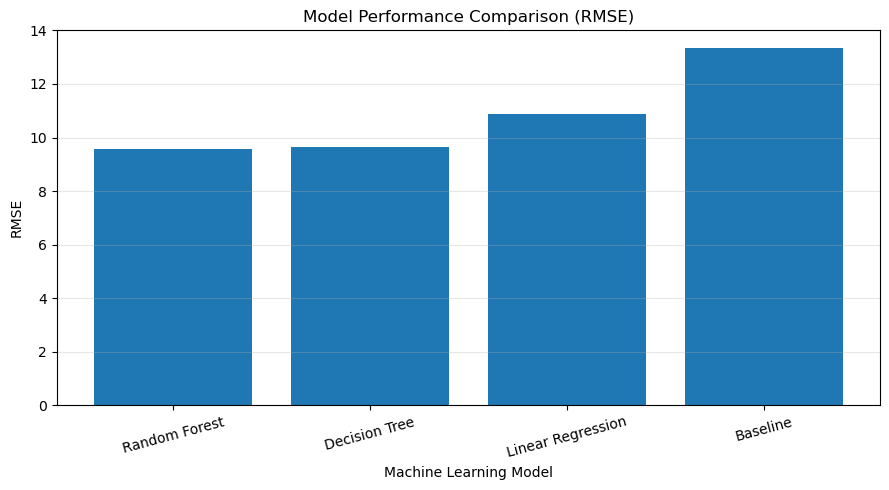

In [4]:
# Compare model performance using RMSE

plt.figure(figsize=(9, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["RMSE"]
)

plt.xlabel("Machine Learning Model")
plt.ylabel("RMSE")
plt.title("Model Performance Comparison (RMSE)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

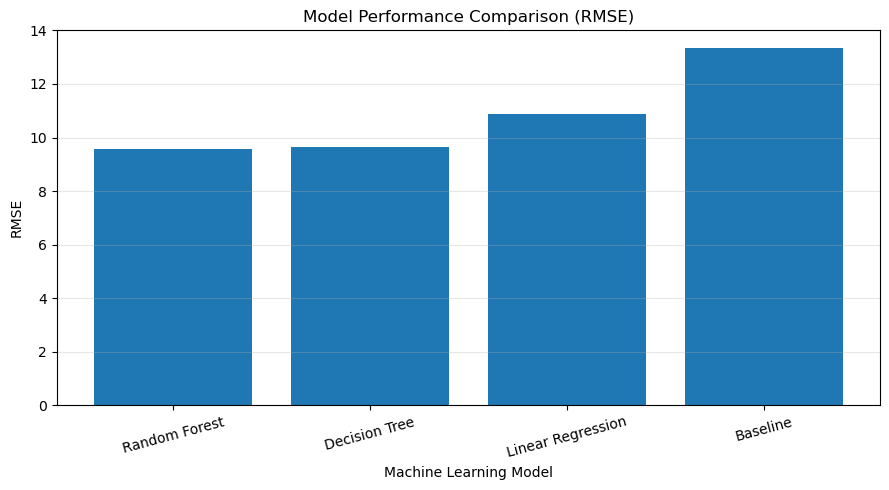

Comparison graph saved successfully!
Location: D:\GroundWatch\reports\model_performance_comparison.png


In [5]:
# Save model performance comparison graph

comparison_graph_path = (
    reports_folder / "model_performance_comparison.png"
)

plt.figure(figsize=(9, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["RMSE"]
)

plt.xlabel("Machine Learning Model")
plt.ylabel("RMSE")
plt.title("Model Performance Comparison (RMSE)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    comparison_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison graph saved successfully!")
print("Location:", comparison_graph_path)

In [6]:
# Final model evaluation summary

print("GROUNDWATCH - MODEL EVALUATION SUMMARY")
print("=" * 45)

print("\nModels Evaluated:")
for model_name in model_comparison["Model"]:
    print("-", model_name)

print("\nSelected Model:", best_model_row["Model"])

print("\nEvaluation Metrics:")
print("MAE:", round(best_model_row["MAE"], 4))
print("RMSE:", round(best_model_row["RMSE"], 4))
print("R²:", round(best_model_row["R2"], 4))

print("\nConclusion:")
print(
    "Random Forest achieved the lowest RMSE among the "
    "four evaluated approaches and was selected as the "
    "best-performing model."
)

GROUNDWATCH - MODEL EVALUATION SUMMARY

Models Evaluated:
- Random Forest
- Decision Tree
- Linear Regression
- Baseline

Selected Model: Random Forest

Evaluation Metrics:
MAE: 1.8905
RMSE: 9.555
R²: 0.2135

Conclusion:
Random Forest achieved the lowest RMSE among the four evaluated approaches and was selected as the best-performing model.


In [7]:
# Create the prediction evaluation report

evaluation_report = f"""
# GroundWatch - Prediction Model Evaluation

## 1. Objective

To evaluate the groundwater prediction models and select
the best-performing regression model.

## 2. Models Evaluated

- Baseline
- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor

## 3. Model Comparison

{model_comparison.to_markdown(index=False)}

## 4. Selected Model

**{best_model_row['Model']}**

## 5. Evaluation Metrics

- MAE: {best_model_row['MAE']:.4f}
- RMSE: {best_model_row['RMSE']:.4f}
- R²: {best_model_row['R2']:.4f}

## 6. Evaluation Observations

Random Forest achieved the lowest RMSE among the four
evaluated approaches.

The model was also evaluated separately on known and
unseen stations.

- Known stations: 21,645 records
- Unseen stations: 1,138 records

## 7. Limitations

The R² value indicates modest explanatory performance.
Some large prediction errors were observed.

An extreme groundwater reading of 1374 metres was
identified in the test data. It was retained in the
evaluation and its effect should be considered when
interpreting the results.

## 8. Conclusion

Random Forest was selected as the best-performing model
among the tested approaches. Further validation and
data-quality investigation are necessary before
operational use.
"""

report_path = reports_folder / "prediction_evaluation.md"

report_path.write_text(
    evaluation_report,
    encoding="utf-8"
)

print("Evaluation report saved successfully!")
print("Location:", report_path)

Evaluation report saved successfully!
Location: D:\GroundWatch\reports\prediction_evaluation.md


In [8]:
import sys

# Make the src folder accessible
src_path = str(repo_root / "src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

from prediction import predict_groundwater_level

print("Prediction module imported successfully!")
print("Random Forest model loaded successfully!")

Prediction module imported successfully!
Random Forest model loaded successfully!


In [9]:
# Test the prediction function

historical_readings = [12.5, 13.2, 12.8]

predicted_level = predict_groundwater_level(
    historical_readings,
    "2024-11-25"
)

print("Historical readings:", historical_readings)
print("Predicted groundwater depth:", round(predicted_level, 2), "m bgl")

Historical readings: [12.5, 13.2, 12.8]
Predicted groundwater depth: 11.14 m bgl


In [11]:
# Load engineered groundwater dataset

data_path = data_folder / "groundwater_features.csv"

model_data = pd.read_csv(data_path)

model_data["Data Acquisition Time"] = pd.to_datetime(
    model_data["Data Acquisition Time"],
    format="mixed"
)

print("Dataset loaded successfully!")
print("Shape:", model_data.shape)

Dataset loaded successfully!
Shape: (113310, 31)


In [12]:
# Select one station with sufficient historical readings

station_id = model_data["Station_ID"].value_counts().idxmax()

station_history = (
    model_data[model_data["Station_ID"] == station_id]
    .sort_values("Data Acquisition Time")
)

print("Selected station:", station_id)
print("Historical records:", len(station_history))

display(
    station_history[
        ["Data Acquisition Time",
         "Groundwater Level Quarterly Manual (meter)"]
    ].tail(5)
)

Selected station: Vishwanathapura_Bangalore Rural_13.275_77.65
Historical records: 106


,Data Acquisition Time,Groundwater Level Quarterly Manual (meter)
107394,2023-05-25,5.87
109036,2023-08-25,6.10
111140,2023-11-05,4.75
112080,2024-01-05,5.30
113031,2024-08-25,4.45


In [13]:
# Extract the last three actual readings

actual_readings = (
    station_history[
        "Groundwater Level Quarterly Manual (meter)"
    ]
    .tail(3)
    .tolist()
)

print("Station:", station_id)
print("Historical readings:", actual_readings)

# Generate prediction
actual_station_prediction = predict_groundwater_level(
    actual_readings,
    "2024-11-25"
)

print(
    "\nPredicted groundwater depth:",
    round(actual_station_prediction, 2),
    "m bgl"
)

Station: Vishwanathapura_Bangalore Rural_13.275_77.65
Historical readings: [4.75, 5.3, 4.45]

Predicted groundwater depth: 4.27 m bgl


In [14]:
try:
    predict_groundwater_level([4.75, 5.30], "2024-11-25")
except ValueError as error:
    print("Validation successful:", error)

Validation successful: At least 3 historical readings are required.


In [15]:
try:
    predict_groundwater_level(
        [4.75, float("nan"), 4.45],
        "2024-11-25"
    )
except ValueError as error:
    print("Validation successful:", error)

Validation successful: Historical readings cannot contain missing values.
